# Krok 1. Podobieństwo lat (E1)
**Wynik z instrukcji:** miara różnicy 2023 vs 2024 i wykres tygodniowy; odpowiedź, czy sezonowa średnia z lat ma sens. Poziom: sklep i asortyment (`AsId`). Dla wszystkich wariantów.

**Pytanie, na które odpowiadamy.** `baseline_0` prognozuje tydzień N jako średnią tygodnia N z lat poprzednich. To ma sens tylko wtedy, gdy rok powtarza swój wzór: te same tygodnie są mocne i słabe. Sprawdzamy to na dwóch latach EDA (2023 i 2024). Rok 2025 jest rokiem testowym i tu go nie oglądamy.

**Jak mierzymy.** Przeskalowujemy rok 2023 do poziomu 2024 (poziom może się zmienić, np. przez wzrost sprzedaży) i sprawdzamy, czy tak przeskalowany wzór trafia w tygodnie 2024 lepiej niż **płaska linia** (każdy tydzień równy średniej roku). Jeśli tak, wzór roczny niesie informację (`ma_sens = True`). Jeśli nie, średnia z lat tylko dodaje szum.

**Wynik zapisany do:** `dane/eda/wynik_01_podobienstwo_lat.csv`.

In [12]:
# Ustawienia wspólne: moduł eda_wspolne.py leży obok tego notebooka
import os, sys
sys.path.insert(0, os.getcwd())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_wspolne as ew

ew.wejdz_do_korzenia()      # przechodzi do katalogu głównego projektu (tam, gdzie jest plik z danymi)
ew.styl()
print("Katalog projektu:", os.getcwd(), "| EDA używa danych do", ew.KONIEC_EDA.date(), "(rok testowy", ew.ROK_TEST, "pomijamy)")

Katalog projektu: /Users/mixer/python/analiza_sprzedazy_w_sklepie | EDA używa danych do 2024-12-31 (rok testowy 2025 pomijamy)


## Dane: tydzień × asortyment
#### Objaśnienie
**Po co.** Porównujemy lata tydzień po tygodniu, więc potrzebujemy sprzedaży tygodniowej. Moduł `eda_wspolne` wczytuje sprzedaż tylko do końca 2024, bez asortymentu 319, i buduje tabelę (wiersze: asortymenty, kolumny: pełne tygodnie od poniedziałku do niedzieli).
**Jak czytać wynik.** Powinno być po 52 tygodnie w każdym roku (2023 i 2024), numerowane tygodniami ISO 1-52. Jeśli liczby się nie zgadzają, dalsze porównanie lat byłoby przesunięte.

In [13]:
fa = ew.wczytaj_sprzedaz()
kal = ew.kalendarz()
tyg_as = ew.panel_tygodniowy(fa, kal, "AsId")          # asortymenty x tygodnie
tyg_sklep = tyg_as.sum()                               # cały sklep (bez AsId 319)
del fa

iso = tyg_as.columns.isocalendar()
rok_tyg = pd.Series(tyg_as.columns.year, index=tyg_as.columns)
t23 = [i for i, d in enumerate(tyg_as.columns) if d.year == 2023]
t24 = [i for i, d in enumerate(tyg_as.columns) if d.year == 2024]
assert len(t23) == len(t24) == 52, (len(t23), len(t24))
assert list(iso.week.values[t23]) == list(range(1, 53)) and list(iso.week.values[t24]) == list(range(1, 53))
print("Asortymentów:", tyg_as.shape[0], "| tygodni 2023:", len(t23), "| tygodni 2024:", len(t24))

# Tygodnie wielkanocne (Wielkanoc przesuwa się między latami, więc osobno sprawdzimy jej wpływ)
wlk_dni = kal.index[kal["OknoWielkanocne"]]
tyg_wlk = pd.DatetimeIndex(sorted(set(wlk_dni - pd.to_timedelta(wlk_dni.dayofweek, unit="D"))))
wlk_maska = np.array([d in tyg_wlk for d in tyg_as.columns])
print("Tygodnie z oknem wielkanocnym:", [str(d.date()) for d in tyg_wlk])

Asortymentów: 235 | tygodni 2023: 52 | tygodni 2024: 52
Tygodnie z oknem wielkanocnym: ['2023-04-03', '2023-04-10', '2023-04-17', '2024-03-25', '2024-04-01', '2024-04-08']


## Poziom: sumy roczne
#### Objaśnienie
**Po co.** Zanim porównamy kształt lat, rozdzielamy dwie rzeczy: zmianę poziomu (sklep sprzedaje więcej lub mniej) i zmianę wzoru (te same tygodnie mocne lub słabe). Tu liczymy poziom: sumy roczne sklepu i zmianę procentową, a niżej to samo dla największych asortymentów.
**Jak czytać wynik.** Zmiana o kilka procent to zwykła wahliwość. Zmiana rzędu kilkunastu procent lub więcej oznacza, że rok 2024 trzeba przeskalować, zanim porówna się go z 2023 (robi to miara niżej). Asortymenty ze skrajnym stosunkiem (bardzo mały lub bardzo duży) to kandydaci do pytania: czy towar pojawił się lub zniknął w trakcie roku.

In [14]:
s23, s24 = tyg_sklep.values[t23].sum(), tyg_sklep.values[t24].sum()
print(f"Sklep (bez AsId 319): 2023 = {s23:,.0f} szt. | 2024 = {s24:,.0f} szt. | zmiana {100 * (s24 / s23 - 1):+.1f} %".replace(",", " "))

poziom = pd.DataFrame({"2023": tyg_as.values[:, t23].sum(axis=1), "2024": tyg_as.values[:, t24].sum(axis=1)}, index=tyg_as.index)
poziom["suma_2023_24"] = poziom["2023"] + poziom["2024"]
poziom["2024/2023"] = poziom["2024"] / poziom["2023"].where(poziom["2023"] > 0)
poziom["udzial_%"] = 100 * poziom["suma_2023_24"] / poziom["suma_2023_24"].sum()
poziom = poziom.sort_values("suma_2023_24", ascending=False)
print("\nNajwiększe asortymenty:")
print(poziom.drop(columns="suma_2023_24").head(12).round(2).to_string())
print("\nStosunek 2024/2023 dla wszystkich asortymentów:", poziom["2024/2023"].describe()[["min", "25%", "50%", "75%", "max"]].round(2).to_dict())
ew.zapisz_wynik(poziom, "wynik_01_poziom_lat.csv")

Sklep (bez AsId 319): 2023 = 1 178 672 szt. | 2024 = 1 183 978 szt. | zmiana +0.5 %

Największe asortymenty:
         2023     2024  2024/2023  udzial_%
AsId                                       
119   58206.0  64215.0       1.10      5.18
102   45091.0  46740.0       1.04      3.89
322   46350.0  42680.0       0.92      3.77
326   46238.0  41128.0       0.89      3.70
217   44547.0  41835.0       0.94      3.66
86    35644.0  37639.0       1.06      3.10
75    26164.0  27996.0       1.07      2.29
219   26390.1  26619.0       1.01      2.24
98    25447.0  27514.0       1.08      2.24
95    25415.0  27123.0       1.07      2.22
313   24099.0  26566.0       1.10      2.14
99    23710.0  25509.0       1.08      2.08

Stosunek 2024/2023 dla wszystkich asortymentów: {'min': 0.0, '25%': 0.9, '50%': 1.03, '75%': 1.17, 'max': 25.0}
Zapisano: dane/eda/wynik_01_poziom_lat.csv (235 wierszy)


'dane/eda/wynik_01_poziom_lat.csv'

## Wykres tygodniowy: sklep 2023 vs 2024
#### Objaśnienie
**Po co.** Zanim policzymy miarę, patrzymy. Rysujemy dwa lata na jednej osi (numer tygodnia ISO), a pod spodem stosunek 2024 do 2023 w każdym tygodniu. Jasne pasy to tygodnie wielkanocne obu lat.
**Jak czytać wynik.** Jeśli linie mają podobny kształt (szczyty i doliny w tych samych tygodniach), wzór roczny się powtarza. Stosunek bliski stałej wartości oznacza zmianę poziomu bez zmiany wzoru. Skoki stosunku w tygodniach wielkanocnych oznaczają, że Wielkanoc w obu latach wypadła w różnych tygodniach.

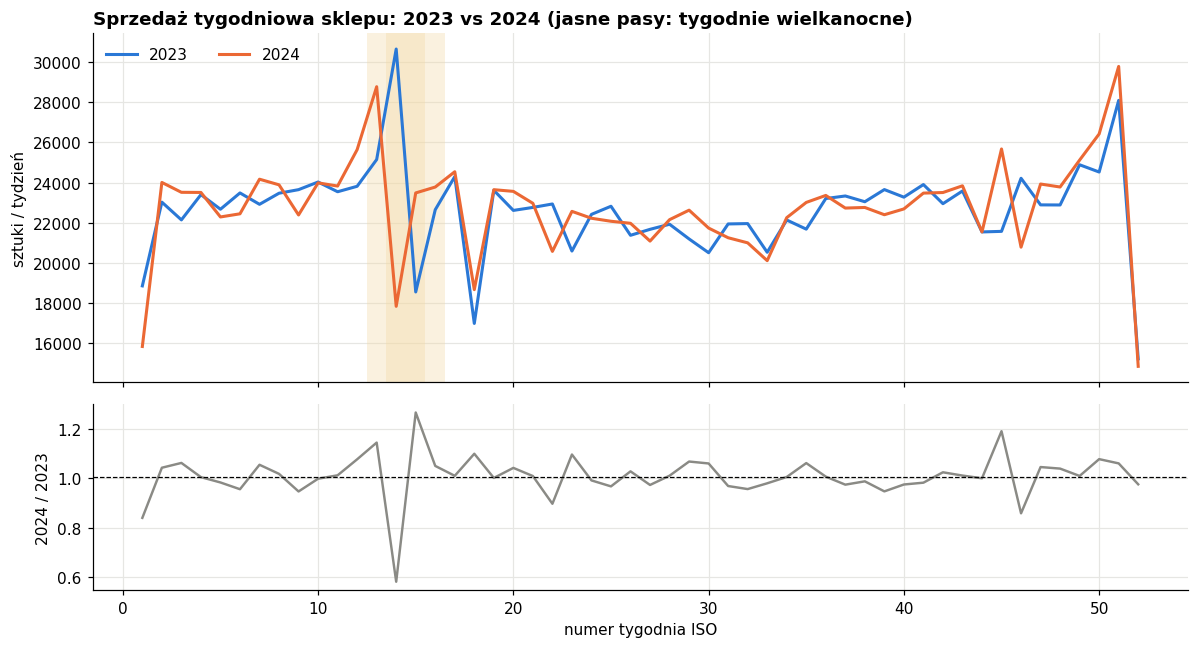

In [15]:
y23, y24 = tyg_sklep.values[t23], tyg_sklep.values[t24]
tyg_nr = np.arange(1, 53)
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1.6]})
ax[0].plot(tyg_nr, y23, color=ew.NIEB, lw=2, label="2023")
ax[0].plot(tyg_nr, y24, color=ew.POM, lw=2, label="2024")
for m in (wlk_maska[t23], wlk_maska[t24]):
    for n in tyg_nr[m]:
        ax[0].axvspan(n - 0.5, n + 0.5, color="#f3d9a4", alpha=0.35, lw=0)
ax[0].set_title("Sprzedaż tygodniowa sklepu: 2023 vs 2024 (jasne pasy: tygodnie wielkanocne)")
ax[0].set_ylabel("sztuki / tydzień"); ax[0].legend(frameon=False, ncol=2)
ax[1].plot(tyg_nr, y24 / y23, color=ew.SZARY, lw=1.6)
ax[1].axhline(y24.sum() / y23.sum(), color="black", lw=0.8, ls="--")
ax[1].set_ylabel("2024 / 2023"); ax[1].set_xlabel("numer tygodnia ISO")
plt.tight_layout(); plt.show()

## Miara podobieństwa
#### Objaśnienie
**Po co.** Zamieniamy wrażenie z wykresu na liczby, które można porównać między asortymentami.
**Miary.**
- **korelacja**: czy tygodnie mocne w 2023 są mocne w 2024 (1 = ten sam kształt, 0 = brak związku).
- **wape_sezon_%**: błąd prognozy „2024 = 2023 przeskalowany do poziomu 2024” (suma |błąd| / suma sprzedaży).
- **wape_plaski_%**: błąd prognozy „każdy tydzień 2024 = średnia 2024”. To poprzeczka: wzór roczny ma sens, jeśli ją pokonuje.
- **poziom_24_do_23**: stosunek sprzedaży rocznej (zmiana poziomu).
**Dlaczego dwie wersje.** „Wszystkie tygodnie” pokazują całość, a „bez okien wielkanocnych” wyłączają tygodnie, w których Wielkanoc rozjeżdża się między latami. Różnica między wersjami mierzy, ile tracimy, nie wyrównując Wielkanocy (krok 5).

**ma_sens** odpowiada na jedno pytanie: czy wzór roczny z 2023 przewidział tygodnie 2024 lepiej niż płaska linia?

True – błąd prognozy sezonowej jest mniejszy niż płaskiej (wape_sezon_% < wape_plaski_%).
False – wzór z 2023 nie pomógł, a nawet zaszkodził.

In [16]:
def miary(a, b, maska=None):
    # a = rok wcześniejszy (2023), b = rok późniejszy (2024); tygodnie wskazane maską
    m = np.ones(len(a), bool) if maska is None else maska
    a, b = a[m], b[m]
    if a.sum() <= 0 or b.sum() <= 0:
        return {"korelacja": np.nan, "wape_sezon_%": np.nan, "wape_plaski_%": np.nan, "poziom_24_do_23": np.nan}
    prog_sezon = a * (b.sum() / a.sum())                       # kształt 2023 przeskalowany do poziomu 2024
    prog_plaski = np.full(len(b), b.mean())
    kor = np.corrcoef(a, b)[0, 1] if a.std() > 0 and b.std() > 0 else np.nan
    return {"korelacja": kor, "wape_sezon_%": ew.wape(b, prog_sezon), "wape_plaski_%": ew.wape(b, prog_plaski),
            "poziom_24_do_23": b.sum() / a.sum()}

bez_wlk = ~(wlk_maska[t23] | wlk_maska[t24])
sklep = pd.DataFrame({"wszystkie tygodnie": miary(y23, y24), "bez okien wielkanocnych": miary(y23, y24, bez_wlk)}).T
print("Sklep (bez AsId 319):")
print(sklep.round(2).to_string())

wiersze = []
for asid, w in tyg_as.iterrows():
    a, b = w.values[t23], w.values[t24]
    m1, m2 = miary(a, b), miary(a, b, bez_wlk)
    wiersze.append({"AsId": asid, "sprzedaz_2023_24": a.sum() + b.sum(), **m1,
                    "wape_sezon_bez_wlk_%": m2["wape_sezon_%"], "wape_plaski_bez_wlk_%": m2["wape_plaski_%"]})
wyn = pd.DataFrame(wiersze).set_index("AsId")
wyn["udzial_%"] = 100 * wyn["sprzedaz_2023_24"] / wyn["sprzedaz_2023_24"].sum()
wyn["zysk_%"] = 100 * (wyn["wape_plaski_%"] - wyn["wape_sezon_%"]) / wyn["wape_plaski_%"]      # o ile wzór roczny poprawia płaską linię
wyn["ma_sens"] = wyn["wape_sezon_%"] < wyn["wape_plaski_%"]
wyn["ma_sens_bez_wlk"] = wyn["wape_sezon_bez_wlk_%"] < wyn["wape_plaski_bez_wlk_%"]
wyn = wyn.sort_values("udzial_%", ascending=False)
print("\nAsortymenty (największe):")
print(wyn.drop(columns="sprzedaz_2023_24").head(12).round(2).to_string())

Sklep (bez AsId 319):
                         korelacja  wape_sezon_%  wape_plaski_%  poziom_24_do_23
wszystkie tygodnie            0.52          5.69           7.29             1.00
bez okien wielkanocnych       0.83          4.11           6.76             1.01

Asortymenty (największe):
      korelacja  wape_sezon_%  wape_plaski_%  poziom_24_do_23  wape_sezon_bez_wlk_%  wape_plaski_bez_wlk_%  udzial_%  zysk_%  ma_sens  ma_sens_bez_wlk
AsId                                                                                                                                                  
119        0.72          8.00          10.68             1.10                  7.59                  10.80      5.18   25.03     True             True
102        0.63         13.45          16.40             1.04                 12.79                  16.78      3.89   17.98     True             True
322        0.46          7.76           7.91             0.92                  6.99                   7.

## Prognoza, którą oceniamy
#### Objaśnienie
**Po co.** Błędy z tabeli wyżej liczą się z dwóch prognoz tygodni 2024, ale dotąd ich nie było widać. Tu je rysujemy. **Prognoza sezonowa** to 2023 przeskalowany do poziomu 2024 (tydzień N z 2023 razy `poziom_24_do_23`). **Prognoza płaska** to średnia tygodniowa 2024 w każdym tygodniu. Czarna linia to rzeczywista sprzedaż 2024.
**Jak czytać wynik.** Odległość linii prognozy od czarnej linii to błąd tygodnia. Jeśli prognoza sezonowa idzie za czarną linią lepiej niż płaska (szczyty i doliny w tych samych tygodniach), wzór roczny działa. Pasy to tygodnie wielkanocne. Zmień `ASID` na numer asortymentu, żeby zobaczyć jego wykres (`None` = cały sklep). Tabela tygodniowych prognoz wszystkich asortymentów trafia do pliku `wynik_01_prognoza_tygodnie.csv`.

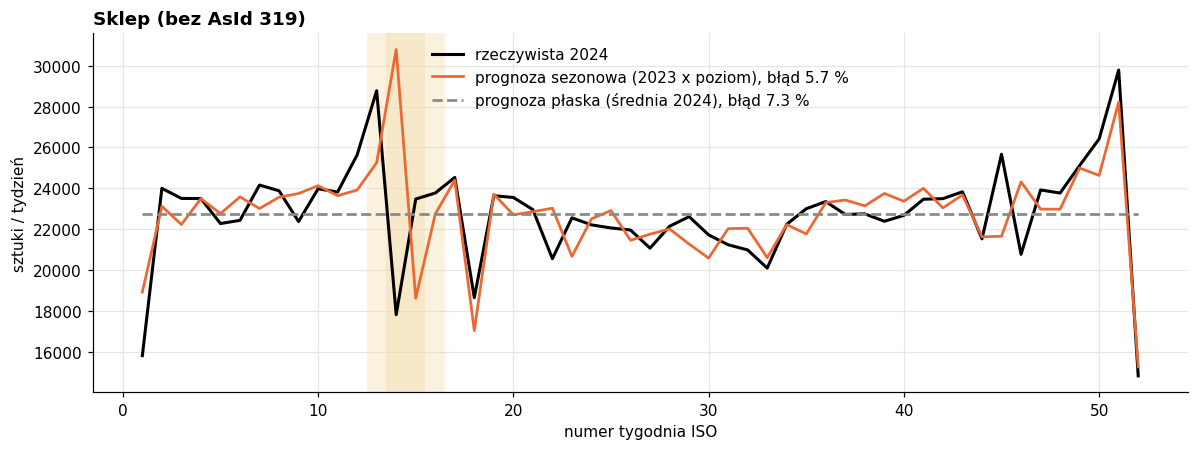

Zapisano: dane/eda/wynik_01_prognoza_tygodnie.csv (11700 wierszy)


'dane/eda/wynik_01_prognoza_tygodnie.csv'

In [17]:
ASID = None          # None = cały sklep; albo numer asortymentu, np. 75 (silny sezon) lub 95 (wzór szkodzi)

def prognozy(a, b):
    return a * (b.sum() / a.sum()), np.full(len(b), b.mean())      # sezonowa, płaska

a, b = (y23, y24) if ASID is None else (tyg_as.loc[ASID].values[t23], tyg_as.loc[ASID].values[t24])
p_sez, p_pl = prognozy(a, b)
fig, ax = plt.subplots(figsize=(11, 4.2))
for m in (wlk_maska[t23], wlk_maska[t24]):
    for n in tyg_nr[m]:
        ax.axvspan(n - 0.5, n + 0.5, color="#f3d9a4", alpha=0.35, lw=0)
ax.plot(tyg_nr, b, color="black", lw=2, label="rzeczywista 2024")
ax.plot(tyg_nr, p_sez, color=ew.POM, lw=1.8, label=f"prognoza sezonowa (2023 x poziom), błąd {ew.wape(b, p_sez):.1f} %")
ax.plot(tyg_nr, p_pl, color=ew.SZARY, lw=1.8, ls="--", label=f"prognoza płaska (średnia 2024), błąd {ew.wape(b, p_pl):.1f} %")
ax.set_title("Sklep (bez AsId 319)" if ASID is None else f"AsId {ASID}")
ax.set_xlabel("numer tygodnia ISO"); ax.set_ylabel("sztuki / tydzień"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

wiersze = []
for asid, w in tyg_as.iterrows():
    aa, bb = w.values[t23], w.values[t24]
    if aa.sum() <= 0 or bb.sum() <= 0:
        continue
    ps, pp = prognozy(aa, bb)
    wiersze.append(pd.DataFrame({"AsId": asid, "tydzien_ISO": tyg_nr, "rzeczywista_2024": bb, "prognoza_sezonowa": ps, "prognoza_plaska": pp}))
ew.zapisz_wynik(pd.concat(wiersze, ignore_index=True), "wynik_01_prognoza_tygodnie.csv")

## Wniosek i zapis
#### Objaśnienie
**Po co.** Zbieramy odpowiedź na pytanie z instrukcji: czy sezonowa średnia z lat ma sens, i dla jakiej części sprzedaży.
**Jak czytać wynik.** Podajemy udział sprzedaży asortymentów, w których wzór roczny pokonuje płaską linię. Wysoki udział uzasadnia `baseline_0` jako punkt odniesienia. Niski oznacza, że sezon roczny jest słaby lub niestabilny, i wtedy ważniejszy jest aktualny poziom (okno historii, krok 3). Uwaga: z dwóch lat nie da się ocenić stabilności wzoru dokładniej niż „powtórzył się raz”.

In [18]:
udzial_sens = wyn.loc[wyn["ma_sens"], "udzial_%"].sum()
print(f"Asortymenty, w których wzór roczny pokonuje płaską linię: {int(wyn['ma_sens'].sum())} z {len(wyn)} "
      f"(udział w sprzedaży: {udzial_sens:.1f} %)")
print(f"Po wyłączeniu tygodni wielkanocnych: {int(wyn['ma_sens_bez_wlk'].sum())} z {len(wyn)} "
      f"({wyn.loc[wyn['ma_sens_bez_wlk'], 'udzial_%'].sum():.1f} %)")
sk = sklep.loc["wszystkie tygodnie"]
print(f"Sklep: korelacja {sk['korelacja']:.2f}, błąd wzoru rocznego {sk['wape_sezon_%']:.1f} % wobec {sk['wape_plaski_%']:.1f} % dla płaskiej linii")
ew.zapisz_wynik(wyn, "wynik_01_podobienstwo_lat.csv")

Asortymenty, w których wzór roczny pokonuje płaską linię: 63 z 235 (udział w sprzedaży: 56.0 %)
Po wyłączeniu tygodni wielkanocnych: 73 z 235 (62.9 %)
Sklep: korelacja 0.52, błąd wzoru rocznego 5.7 % wobec 7.3 % dla płaskiej linii
Zapisano: dane/eda/wynik_01_podobienstwo_lat.csv (235 wierszy)


'dane/eda/wynik_01_podobienstwo_lat.csv'